# 01 · Exploratory Data Analysis

**Goal:** understand the dataset, assess data quality and integrity, and list every issue that has to be handled before modelling.

Notebooks in this project:
1. **01_eda** – findings (this notebook)
2. **02_modelling** – candidate models, feature selection, comparison, selection (development evidence)
3. **03_validation_and_verdict** – independent validation, interpretation, production verdict

The actions decided here are implemented in the `pd_model` package: the repairs in `pd_model.data.cleaning` and the treatment of missing values, caps and encoding in the preprocessor `pd_model.features.preprocessing`. They run through `scripts/clean_data.py` and `scripts/train.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pd_model.config import load_config
from pd_model.data.loading import load_raw
from pd_model.features.woe import information_value, woe_table
from pd_model.validation.metrics import rate_table, smd

cfg = load_config()
RAW_DATA, TARGET = cfg.paths.raw_data, cfg.target

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Dataset overview

In [2]:
df = load_raw(RAW_DATA)
print(f"Shape: {df.shape}")
print(f"Duplicated rows: {df.duplicated().sum()}")
df.head()

Shape: (20000, 16)
Duplicated rows: 0


,client_history_in_bank,age,income,employment_years,loan_amount,interest_rate,num_loans,credit_utilization,past_due_30,past_due_60,past_due_90,past_default,recovery_flag_after_90d,dti,region_risk,default
0,57,30.0987,"28,095.3910",6.5205,"6,930.8831",0.1309,2,0.2465,1,0,0,0,1,0.2467,0,0
1,5,37.9235,"13,880.7267",4.5765,"5,489.3074",0.1309,1,0.0721,2,1,0,0,0,0.3955,0,0
2,50,23.2133,"15,692.3808",6.0538,"22,179.1647",0.1665,4,0.1191,0,0,0,0,0,1.4134,0,0
3,2,72.8324,"30,000.0000",3.3526,"12,616.2545",0.1061,2,0.1806,1,0,0,0,0,0.4205,1,0
4,4,29.6279,"29,162.0489",13.5491,"18,788.1356",0.0900,5,0.4582,0,2,0,0,0,0.6443,0,0


In [3]:
df.dtypes.to_frame("dtype").T

,client_history_in_bank,age,income,employment_years,loan_amount,interest_rate,num_loans,credit_utilization,past_due_30,past_due_60,past_due_90,past_default,recovery_flag_after_90d,dti,region_risk,default
dtype,int64,float64,float64,float64,float64,float64,int64,float64,int64,int64,int64,int64,int64,float64,int64,int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
client_history_in_bank,"20,000.0000",29.9234,17.0766,1.0000,15.0000,30.0000,45.0000,59.0000
age,"20,000.0000",38.8600,12.0861,21.0000,30.0353,38.1821,46.3525,99.0000
income,"19,300.0000","27,028.4292","5,198.3558","3,014.1761","25,467.3555","30,000.0000","30,000.0000","30,000.0000"
employment_years,"20,000.0000",6.1137,3.7648,0.0000,3.3124,5.9597,8.6600,20.7019
loan_amount,"20,000.0000","13,093.4878","14,885.6504",385.9665,"6,163.2130","9,941.7723","16,078.1571","800,000.0000"
interest_rate,"20,000.0000",0.1198,0.0299,0.0300,0.0995,0.1201,0.1399,0.2428
num_loans,"20,000.0000",3.0017,1.7512,0.0000,2.0000,3.0000,4.0000,13.0000
credit_utilization,"19,983.0000",0.3374,0.1792,0.0022,0.1979,0.3192,0.4588,0.9717
past_due_30,"20,000.0000",0.4027,0.6327,0.0000,0.0000,0.0000,1.0000,4.0000
past_due_60,"20,000.0000",0.1999,0.4470,0.0000,0.0000,0.0000,0.0000,4.0000


### 1.1 Index integrity and data provenance

In [5]:
print("index unique:", df.index.is_unique, "| duplicated index labels:", df.index.duplicated().sum(),
      "| index range:", df.index.min(), "–", df.index.max())
breaks = np.where(np.diff(df.index.to_numpy()) != 1)[0]
print("index restarts at row position(s):", breaks + 1)

index unique: False | duplicated index labels: 7000 | index range: 0 – 12999
index restarts at row position(s): [13000]


The index is **not unique**: it runs 0–12,999 and then restarts at 0 for the last 7,000 rows. The file is a **concatenation of 2 blocks** (13,000 + 7,000 rows). Label-based joins on this index would silently duplicate rows, so we reset it and keep the block id as provenance.

In [6]:
df = df.reset_index(drop=True)
df["block"] = np.where(df.index < 13_000, 1, 2)
blk = df.groupby("block").agg(rows=(TARGET, "size"), default_rate=(TARGET, "mean"),
                              income_missing=("income", lambda s: s.isna().sum()),
                              util_missing=("credit_utilization", lambda s: s.isna().sum()),
                              age_99=("age", lambda s: (s == 99).sum()),
                              loan_max=("loan_amount", "max"),
                              income_min=("income", "min"))
blk = blk.join(rate_table(df.block, df[TARGET])[["ci_low", "ci_high"]].add_prefix("dr_"))
blk

,rows,default_rate,income_missing,util_missing,age_99,loan_max,income_min,dr_ci_low,dr_ci_high
block,,,,,,,,,
1,13000,0.1573,0,0,0,"80,000.0000","3,014.1761",0.1512,0.1637
2,7000,0.1573,700,17,120,"800,000.0000","16,817.0646",0.1489,0.1660


The 2 blocks have identical default rates (overlapping 95% Wilson intervals), but **all** the missing incomes, all the missing utilisation values, every `age = 99` and the 800k loans sit in **block 2**. Block 1 looks like the clean source, while block 2 has had quality problems introduced. We use the block id throughout the analysis below and as a validation segment in notebook 03 (it is never a model feature).

### 1.2 Feature distributions by block
To check whether block 2 differs from block 1 beyond the obvious corruption, we compare every feature with the **standardised mean difference** (SMD = (mean₂ − mean₁) / pooled SD) and the 2-sample Kolmogorov-Smirnov (KS) test. Rule of thumb: |SMD| < 0.1 is negligible. With 13k vs 7k rows even tiny shifts become "significant", so we read the SMD (effect size) first and the p-value second.

In [7]:
from scipy.stats import ks_2samp

b1_, b2_ = df[df.block == 1], df[df.block == 2]
feat_cols = [c for c in df.columns if c not in ("block",)]
smd_tbl = pd.DataFrame({
    "mean_block1": b1_[feat_cols].mean(),
    "mean_block2": b2_[feat_cols].mean(),
    "smd": {c: smd(b1_[c], b2_[c]) for c in feat_cols},
    "ks_p": {c: ks_2samp(b1_[c].dropna(), b2_[c].dropna()).pvalue for c in feat_cols}})
smd_tbl = smd_tbl.reindex(smd_tbl.smd.abs().sort_values(ascending=False).index)
smd_tbl["ks_p"] = smd_tbl.ks_p.map(lambda v: f"{v:.2g}")
smd_tbl

,mean_block1,mean_block2,smd,ks_p
income,"26,566.7394","27,981.1226",0.2936,3.4e-38
age,38.4633,39.5967,0.0910,0.016
loan_amount,"12,665.5564","13,888.2175",0.0738,0.62
past_due_90,0.0500,0.0447,-0.0245,1
employment_years,6.1371,6.0704,-0.0177,0.38
past_due_60,0.1972,0.2050,0.0174,0.94
client_history_in_bank,30.0075,29.7673,-0.0141,0.81
dti,0.5188,0.5133,-0.0114,0.83
interest_rate,0.1199,0.1196,-0.0095,0.37
region_risk,0.4995,0.5057,0.0091,0.7


Apart from the known corruption, **the 2 blocks come from the same population**:
- Only 3 features show any shift, and each one is explained by a corruption already found:
    - `income` (SMD 0.29, because block 2's low incomes were deleted, §7.1),
    - `age` (0.09, the 120 placeholder 99s),
    - `loan_amount` (mean +0.07, the 80 loans ×10; the KS test doesn't notice because it is only 1% of rows).
- Every other feature, including the target and `dti`, has |SMD| < 0.03 and KS p > 0.3.

So block 2 is not a different time period or segment. It is the same kind of sample with errors injected, which is why it is safe to correct and keep it rather than drop it.

## 2. Target

In [8]:
tgt = df[TARGET].value_counts().to_frame("count")
tgt["share"] = tgt["count"] / len(df)
tgt

,count,share
default,,
0,16854,0.8427
1,3146,0.1573


A default rate of **15.7%** is high for a retail book but leaves plenty of defaults (3,146) for modelling, so no resampling is needed. The class imbalance is moderate and will be handled through probability-based metrics (AUC/Gini/KS, Brier) rather than accuracy.

## 3. Missing values

In [9]:
miss = df.isna().sum().to_frame("n_missing")
miss["share"] = miss.n_missing / len(df)
miss = miss[miss.n_missing > 0]
for c in miss.index:
    rt = rate_table(df[c].isna().map({True: "missing", False: "present"}), df[TARGET])
    miss.loc[c, "dr_if_missing"] = rt.loc["missing", "default_rate"]
    miss.loc[c, "dr_missing_ci"] = f"[{rt.loc['missing', 'ci_low']:.3f}, {rt.loc['missing', 'ci_high']:.3f}]"
    miss.loc[c, "dr_if_present"] = rt.loc["present", "default_rate"]
miss

,n_missing,share,dr_if_missing,dr_missing_ci,dr_if_present
income,700,0.0350,0.2371,"[0.207, 0.270]",0.1544
credit_utilization,17,0.0008,0.1765,"[0.062, 0.410]",0.1573


- `income` is missing for 700 clients (3.5%, all in block 2), and the missingness is **informative**: their default rate is 23.7% vs 15.4%. That points to missing-not-at-random (MNAR). §7.1 shows these values can be **reconstructed exactly**.
- `credit_utilization` is missing for only 17 rows. Its 17.6% default rate looks higher, but the 95% interval is very wide and includes the overall 15.7%, so there is no evidence the missingness is informative. Simple median imputation is enough.

## 4. Distributions

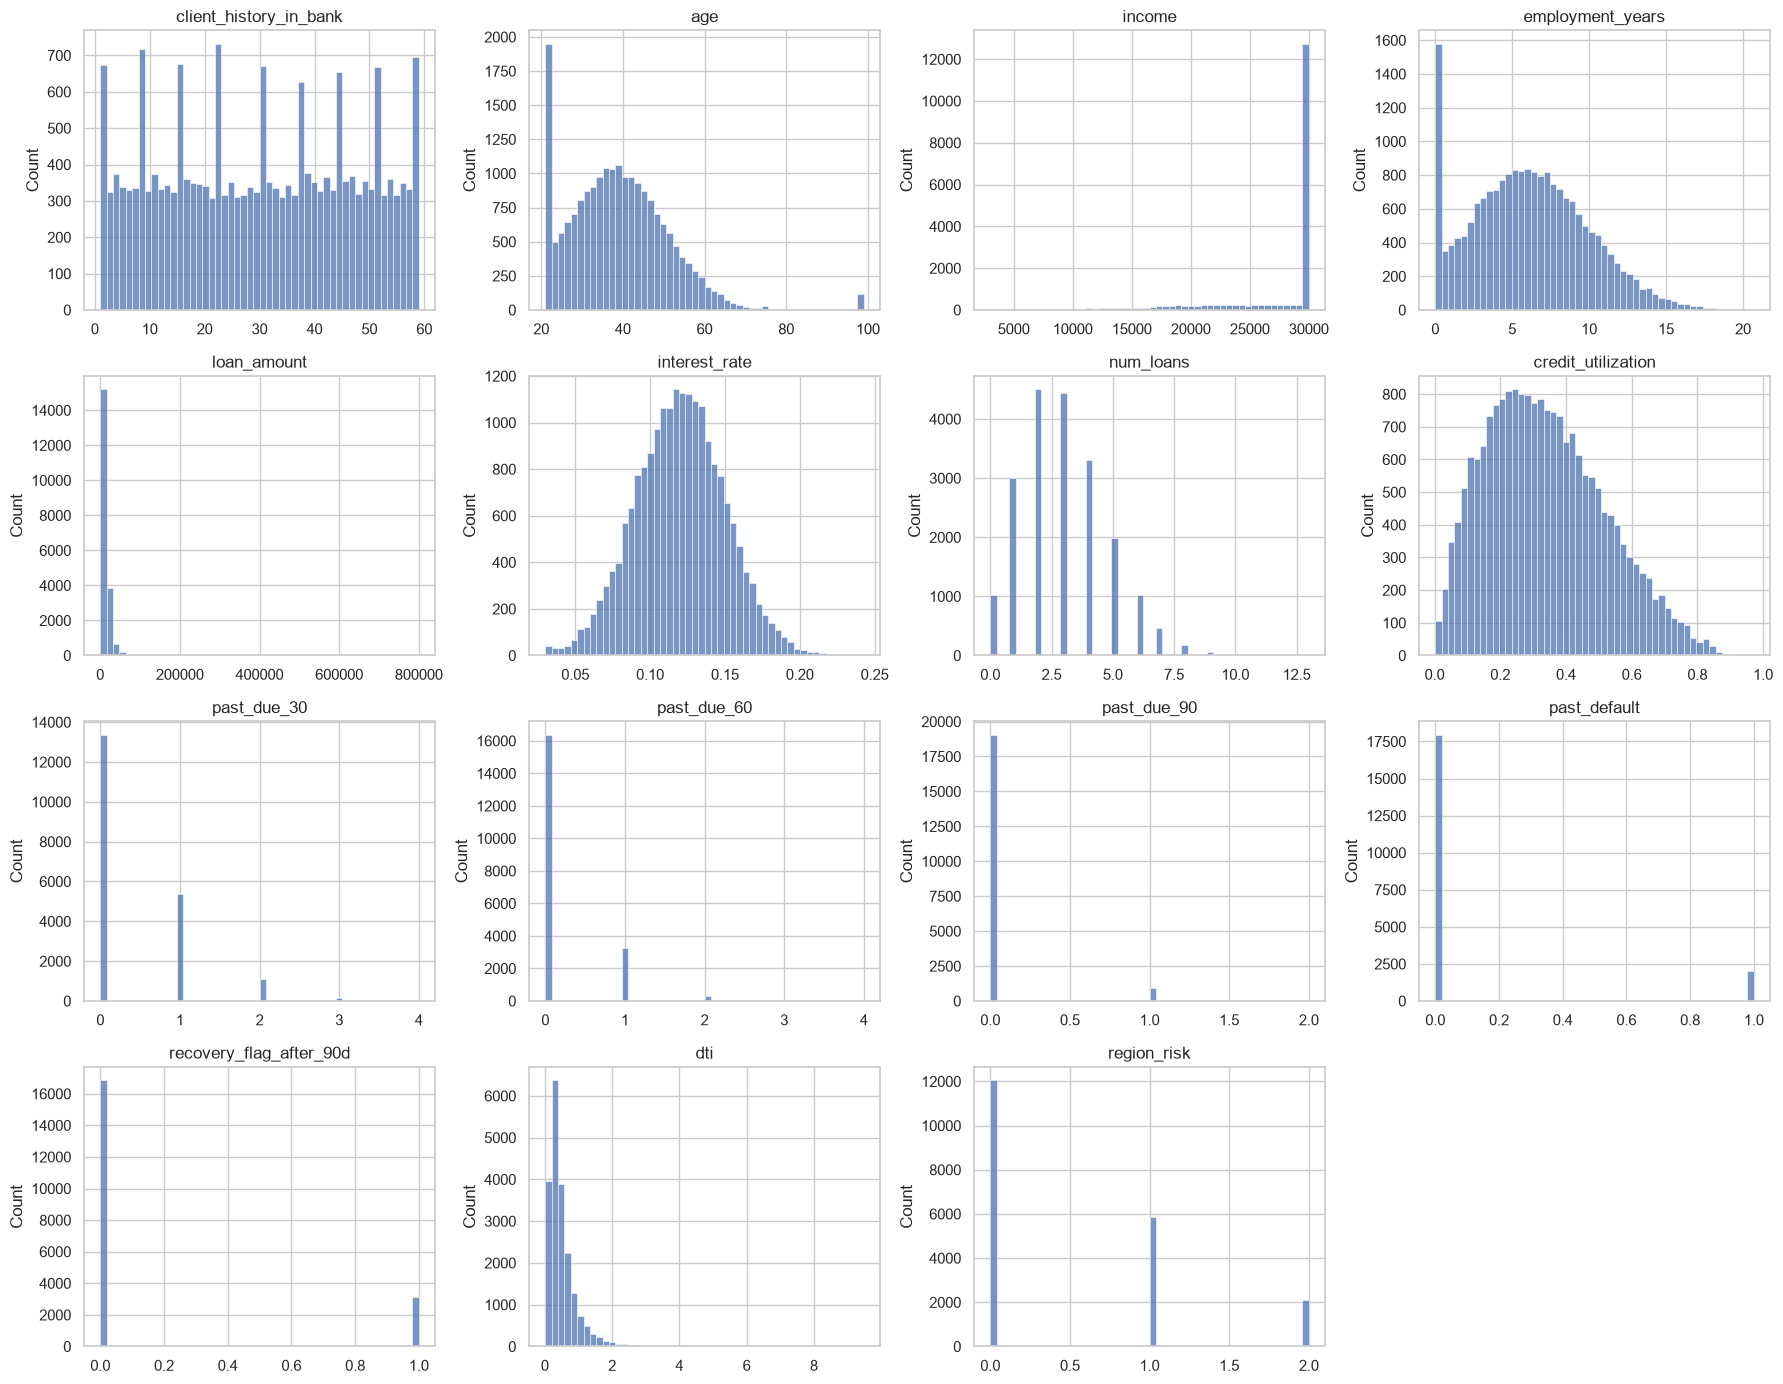

In [10]:
num_cols = [c for c in df.columns if c not in (TARGET, "block")]
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c].dropna(), bins=50, ax=ax, color="#4C72B0")
    ax.set_title(c)
    ax.set_xlabel("")
for ax in axes.flat[len(num_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

## 5. Censoring, caps and placeholder values
The histograms show spikes at the edges of several distributions, so we check for exact repeated values in the continuous variables.

In [11]:
def top_repeated(s, k=3):
    vc = s.value_counts()
    return vc[vc > 1].head(k).to_dict()

cont = ["age", "income", "employment_years", "loan_amount", "interest_rate", "credit_utilization", "dti"]
pd.DataFrame({c: {"n_unique": df[c].nunique(), "min": df[c].min(), "max": df[c].max(),
                  "repeated_values": top_repeated(df[c])} for c in cont}).T

,n_unique,min,max,repeated_values
age,18343,21.0000,99.0000,"{21.0: 1520, 99.0: 120, 75.0: 20}"
income,6796,"3,014.1761","30,000.0000",{30000.0: 12505}
employment_years,18704,0.0000,20.7019,{0.0: 1297}
loan_amount,19979,385.9665,"800,000.0000","{80000.0: 21, 800000.0: 2}"
interest_rate,19984,0.0300,0.2428,{0.03: 17}
credit_utilization,19983,0.0022,0.9717,{}
dti,19986,0.0129,9.4839,{2.6666666665777776: 15}


In [12]:
checks = pd.DataFrame({
    "rows": {
        "income == 30,000 (cap)": (df.income == 30_000).sum(),
        "age == 21 (floor)": (df.age == 21).sum(),
        "age == 99 (placeholder)": (df.age == 99).sum(),
        "interest_rate == 0.03 (floor)": (df.interest_rate == 0.03).sum(),
        "loan_amount == 80,000": (df.loan_amount == 80_000).sum(),
        "loan_amount == 800,000": (df.loan_amount == 800_000).sum(),
        "employment_years == 0": (df.employment_years == 0).sum(),
    }
})
checks["share"] = checks.rows / len(df)
checks

,rows,share
"income == 30,000 (cap)",12505,0.6252
age == 21 (floor),1520,0.0760
age == 99 (placeholder),120,0.0060
interest_rate == 0.03 (floor),17,0.0008
"loan_amount == 80,000",21,0.0010
"loan_amount == 800,000",2,0.0001
employment_years == 0,1297,0.0649


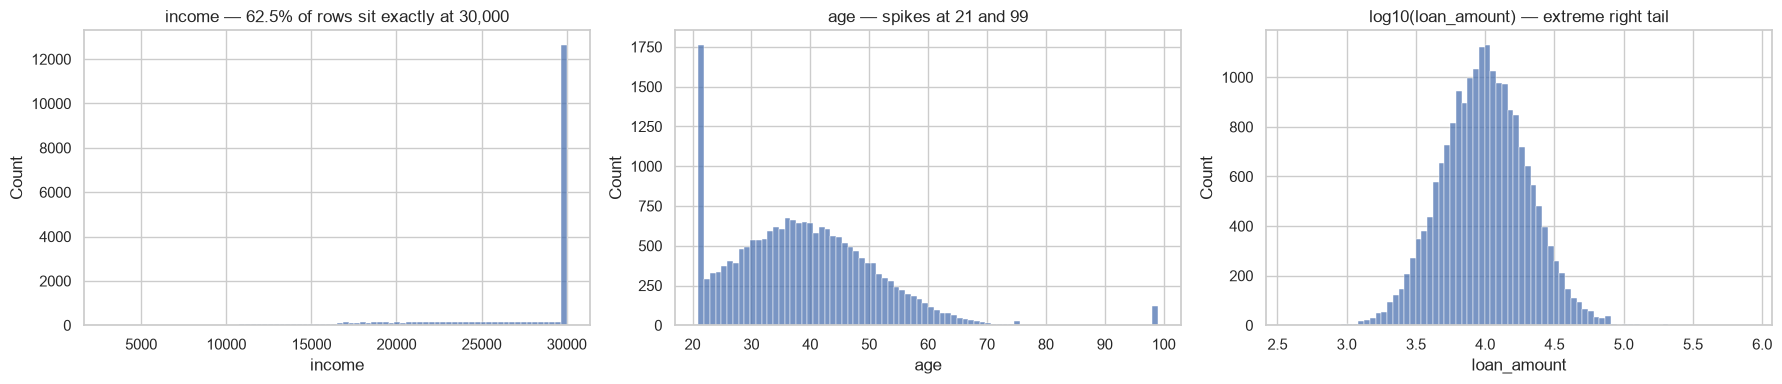

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df.income.dropna(), bins=80, ax=axes[0]); axes[0].set_title("income — 62.5% of rows sit exactly at 30,000")
sns.histplot(df.age, bins=80, ax=axes[1]); axes[1].set_title("age — spikes at 21 and 99")
sns.histplot(np.log10(df.loan_amount), bins=80, ax=axes[2]); axes[2].set_title("log10(loan_amount) — extreme right tail")
plt.tight_layout(); plt.show()

In [14]:
special = {"income capped (30k)": df.income == 30_000, "income missing": df.income.isna(),
           "age == 21": df.age == 21, "age == 99": df.age == 99}
pd.concat({name: rate_table(mask.map({True: "yes", False: "no"}), df[TARGET]) for name, mask in special.items()})

n  defaults  default_rate  ci_low  ci_high
income capped (30k) no    7495      1372        0.1831  0.1745   0.1920
                    yes  12505      1774        0.1419  0.1359   0.1481
income missing      no   19300      2980        0.1544  0.1494   0.1596
                    yes    700       166        0.2371  0.2071   0.2700
age == 21           no   18480      2907        0.1573  0.1521   0.1626
                    yes   1520       239        0.1572  0.1398   0.1764
age == 99           no   19880      3128        0.1573  0.1523   0.1625
                    yes    120        18        0.1500  0.0970   0.2247

**Findings**
- **Income is right-censored at 30,000** for 62.5% of clients, so the median equals the maximum. The variable carries much less information than it appears to, and the derived `dti` is affected too. Capped clients default *less* (14.2% vs 18.3%, non-overlapping 95% intervals), so an `income_capped` flag is informative.
- **Age is clipped to [21, 75]** in both blocks (1,520 rows at 21, 20 at 75), which is part of how the data was generated. **99 is a placeholder** (120 rows, block 2 only, nothing between 75 and 99), so we treat it as missing. Its default rate (15.0%) is indistinguishable from the rest (the interval spans roughly 10–23%), so the placeholder is not informative.
- **Interest rate is floored at 3%** (17 rows), which is plausible as a product minimum.
- **Loan amount has an extreme tail**: 2 loans of exactly 800,000 and 21 of exactly 80,000, against a median of about 10k. Block 1 never exceeds 80,000, so **80k is the product cap**, and 800k looks like 80k with an extra 0. §7.1 shows exactly which loans were multiplied by 10.

## 6. Outliers

In [15]:
q = df[cont].quantile([0.01, 0.5, 0.99, 0.995]).T
q["max"] = df[cont].max()
q["max / p99"] = q["max"] / q[0.99]
q

,0.0100,0.5000,0.9900,0.9950,max,max / p99
age,21.0000,38.1821,69.2573,99.0000,99.0000,1.4295
income,"9,688.2315","30,000.0000","30,000.0000","30,000.0000","30,000.0000",1.0000
employment_years,0.0000,5.9597,15.4027,16.4689,20.7019,1.3440
loan_amount,"1,974.9211","9,941.7723","55,345.2055","69,056.1649","800,000.0000",14.4547
interest_rate,0.0502,0.1201,0.1894,0.1960,0.2428,1.2817
credit_utilization,0.0322,0.3192,0.7777,0.8190,0.9717,1.2495
dti,0.0707,0.3801,2.3548,2.8407,9.4839,4.0275


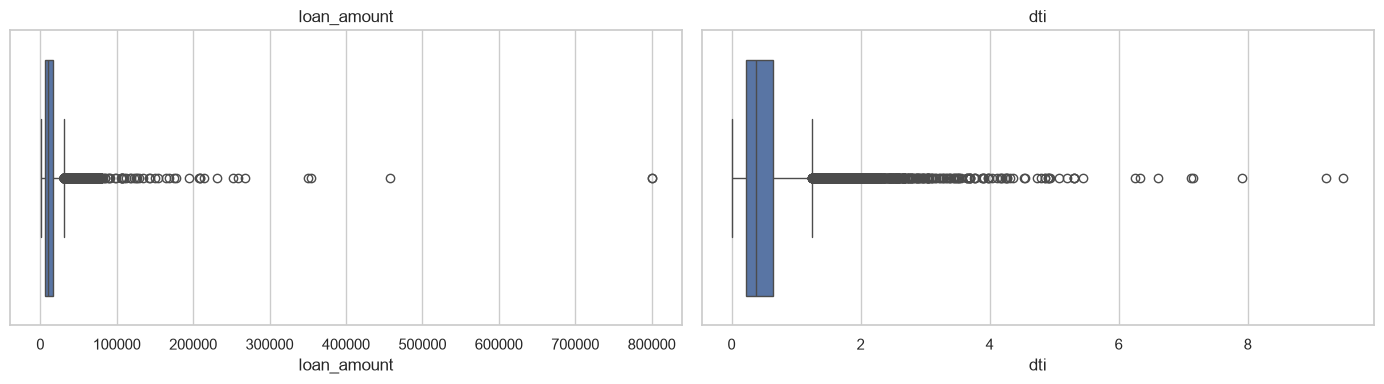

dti > 2: 334  | dti > 5: 14


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df.loan_amount, ax=axes[0]); axes[0].set_title("loan_amount")
sns.boxplot(x=df.dti, ax=axes[1]); axes[1].set_title("dti")
plt.tight_layout(); plt.show()
print("dti > 2:", (df.dti > 2).sum(), " | dti > 5:", (df.dti > 5).sum())

`loan_amount` (max is 13x its 99th percentile) and `dti` (up to 9.5) have heavy tails. The loan tail is mostly a data error (fixed exactly in `pd_model.data.cleaning`). The `dti` tail is genuine: small incomes combined with large loans. Tree models are robust to it, but logistic regression is not, so `dti` will be **winsorised at the training-set 99.5th percentile**.

## 7. Logical consistency checks

In [17]:
r = df
rules = {
    "past_due_90 > past_due_60": r.past_due_90 > r.past_due_60,
    "past_due_60 > past_due_30": r.past_due_60 > r.past_due_30,
    "past_due_30 > num_loans": r.past_due_30 > r.num_loans,
    "sum(past_due_*) > num_loans": (r.past_due_30 + r.past_due_60 + r.past_due_90) > r.num_loans,
    "num_loans == 0 but credit_utilization > 0": (r.num_loans == 0) & (r.credit_utilization > 0),
    "employment_years > age - 14": r.employment_years > r.age - 14,
    "client_history (months) > (age - 18) * 12": r.client_history_in_bank > (r.age - 18) * 12,
    "past_default == 1 but no past due ever": (r.past_default == 1) & (r.past_due_30 + r.past_due_60 + r.past_due_90 == 0),
}
cons = pd.DataFrame({
    "rows": {k: int(v.sum()) for k, v in rules.items()},
    "default_rate": {k: r.loc[v, TARGET].mean() for k, v in rules.items()},
})
cons["share"] = cons.rows / len(df)
cons

,rows,default_rate,share
past_due_90 > past_due_60,797,0.2936,0.0398
past_due_60 > past_due_30,2558,0.2260,0.1279
past_due_30 > num_loans,554,0.2310,0.0277
sum(past_due_*) > num_loans,1008,0.2659,0.0504
num_loans == 0 but credit_utilization > 0,1019,0.1874,0.0510
employment_years > age - 14,970,0.1629,0.0485
client_history (months) > (age - 18) * 12,676,0.1657,0.0338
past_default == 1 but no past due ever,1083,0.2881,0.0541


**Findings**
- **DPD buckets don't nest.** If they were cumulative (every 90+ DPD loan is also 60+ and 30+), we would have `past_due_90 ≤ past_due_60 ≤ past_due_30`. That is violated in 797 and 2,558 rows respectively, so the buckets must be **exclusive** ("worst status reached"). This interpretation should be **confirmed with the data owner**.
- **Past-due counts exceed `num_loans`** in 1,008 rows. That is possible if `num_loans` counts only *active* loans while DPD history covers closed ones too, but it is another definition to confirm.
- **1,019 clients have `num_loans = 0` and still have a utilisation value**, which suggests utilisation covers non-loan products (cards, overdrafts).
- **Biologically implausible combinations:** 970 clients have more employment years than age − 14, and 676 have been with the bank longer than they have been adults. The variables were probably generated independently, so the data looks **synthetic**. All of these violations occur at the **same rate in both blocks**, so they are not part of the block-2 corruption.
- 1,083 clients have `past_default = 1` but no past-due history at all, which adds more uncertainty about definitions.

The **DPD-related violations have higher default rates (23–29%)**. That is expected, because these clients have past-due history by construction, so the rows hold real signal and shouldn't be discarded. The age/tenure/employment violations have a normal default rate (≈16%) and look like random noise. We **keep all rows** (dropping 10–15% of the data would bias the sample), add an `inconsistent_record` flag that is used **only for validation segmentation** (not as a model feature), and record the issue as a **data-quality limitation** for model risk.

### 7.1 How `dti` is built, and recovering the corrupted values

In [18]:
ratio = df.loan_amount / df.income
print("corr(dti, loan/income) by block:", {b: round(ratio[df.block == b].corr(df.dti[df.block == b]), 4) for b in (1, 2)})
b1 = df[df.block == 1]
print("block 1: max |dti − loan/income| =", f"{(b1.dti - b1.loan_amount / b1.income).abs().max():.1e}")

corr(dti, loan/income) by block: {1: np.float64(1.0), 2: np.float64(0.5536)}
block 1: max |dti − loan/income| = 2.3e-09


In block 1, **`dti` is exactly `loan_amount / income`** (to 1e-6). Despite its name, it is a **loan-to-income ratio for this loan**, not total debt-to-income. In block 2 the identity breaks. Because `dti` itself was left intact, we can use it to see what was changed:

In [19]:
b2 = df[df.block == 2].copy()
b2["loan_over_dti_income"] = b2.loan_amount / (b2.dti * b2.income)
b2["implied_income"] = b2.loan_amount / b2.dti
print("block 2, ratio loan / (dti × income):")
print(b2.loan_over_dti_income.round(3).value_counts(dropna=False).head())

block 2, ratio loan / (dti × income):
loan_over_dti_income
1.0000     6227
NaN         700
10.0000      73
Name: count, dtype: int64


In [20]:
x10 = np.isclose(b2.loan_over_dti_income, 10, rtol=1e-4) | (b2.income.isna() & (b2.implied_income > 30_000))
miss = b2.income.isna()
print(f"loans inflated ×10: {x10.sum()}  (implied income above the 30k cap is impossible)")
print(f"missing incomes: {miss.sum()} → implied income (loan / dti), after fixing ×10 loans:")
implied = np.where(x10, b2.loan_amount / 10, b2.loan_amount) / b2.dti
print(pd.Series(implied[miss]).describe().round(0))
print(f"\nincome < 16,800 in block 1: {(b1.income < 16_800).mean():.1%} of rows | in block 2 (observed): {(b2.income < 16_800).mean():.1%}")

loans inflated ×10: 80  (implied income above the 30k cap is impossible)
missing incomes: 700 → implied income (loan / dti), after fixing ×10 loans:
count      700.0000
mean    13,275.0000
std      2,649.0000
min      4,913.0000
25%     11,553.0000
50%     13,836.0000
75%     15,329.0000
max     16,814.0000
Name: dti, dtype: float64

income < 16,800 in block 1: 10.1% of rows | in block 2 (observed): 0.0%


**2 kinds of corruption, both reversible:**
- **80 loan amounts in block 2 were multiplied by 10**, including the two 800k loans. For 73 of them, `loan / (dti × income)` is exactly 10. The other 7 have missing income, and their implied income would exceed the 30k cap, which is impossible. They are corrected by dividing by 10. §7.2 shows why the **loan** is the corrupted value, not `dti` or income.
- **The 700 missing incomes are exactly the low ones.** Every block-2 income below about 16.8k was deleted: the implied incomes of the missing rows top out at 16,814, and the lowest observed block-2 income is 16,817. That is 10% of block 2, the same share of sub-16.8k incomes as in block 1. This is threshold-based missing-not-at-random, and it explains why "missing income" defaults more often (23.7%). Since `dti = loan / income`, **income can be reconstructed exactly** as `loan / dti`. Simple median imputation would have put these low-income, high-risk clients at the 30k cap: exactly the wrong answer.

A side effect for modelling: `loan_amount`, `income` and `dti` are **deterministically linked**, so a model needs at most 2 of them.

### 7.2 Which value was corrupted: loan, dti or income?
The identity `loan = dti × income` only says that **1** of the 3 values in these 80 rows is off by a factor of 10, not which one. 3 explanations are possible:

| Hypothesis | Correction |
|---|---|
| H1: loan ×10 | loan ÷ 10 |
| H2: dti ÷10 | dti × 10 |
| H3: income ÷10 | income × 10 |

The test: the corrupted variable should look **abnormal before** the fix and **normal after** it. We compare each value in the 80 suspicious rows with the clean block 1 using a 2-sample Kolmogorov–Smirnov (KS) test, which checks whether 2 samples could come from the same distribution.

In [21]:
from scipy.stats import ks_2samp

sus = b2[x10]
ks = lambda a, b: ks_2samp(a.dropna(), b.dropna()).pvalue
sus_inc = sus.income.dropna()
hyp = pd.DataFrame({
    "raw value vs block 1 (KS p)": {
        "H1: loan ×10": ks(sus.loan_amount, b1.loan_amount),
        "H2: dti ÷10": ks(sus.dti, b1.dti),
        "H3: income ÷10": ks(sus_inc, b1.income),
    },
    "corrected value vs block 1 (KS p)": {
        "H1: loan ×10": ks(sus.loan_amount / 10, b1.loan_amount),
        "H2: dti ÷10": ks(sus.dti * 10, b1.dti),
        "H3: income ÷10": ks(sus_inc * 10, b1.income),
    },
    "corrected value breaks a hard limit": {
        "H1: loan ×10": f"{(sus.loan_amount / 10 > b1.loan_amount.max()).sum()} of {len(sus)} above the 80k loan cap",
        "H2: dti ÷10": f"{(sus.dti * 10 > b1.dti.max()).sum()} of {len(sus)} above block-1 max dti ({b1.dti.max():.2f})",
        "H3: income ÷10": f"{(sus_inc * 10 > 30_000).sum()} of {len(sus_inc)} above the 30k income cap",
    },
})
pcols = ["raw value vs block 1 (KS p)", "corrected value vs block 1 (KS p)"]
hyp[pcols] = hyp[pcols].map(lambda v: f"{v:.2g}")
hyp

,raw value vs block 1 (KS p),corrected value vs block 1 (KS p),corrected value breaks a hard limit
H1: loan ×10,4.7e-86,0.76,0 of 80 above the 80k loan cap
H2: dti ÷10,0.83,9.9e-75,10 of 80 above block-1 max dti (9.21)
H3: income ÷10,0.26,0,73 of 73 above the 30k income cap


In [22]:
q = [0.01, 0.25, 0.5, 0.75, 0.99]
pd.DataFrame({
    "block 1 loan": b1.loan_amount.quantile(q).values,
    "suspicious loan (raw)": sus.loan_amount.quantile(q).values,
    "suspicious loan ÷ 10": (sus.loan_amount / 10).quantile(q).values,
    "block 1 dti": b1.dti.quantile(q).values,
    "suspicious dti (raw)": sus.dti.quantile(q).values,
    "suspicious dti × 10": (sus.dti * 10).quantile(q).values,
}, index=[f"p{int(x*100)}" for x in q]).round(3)

,block 1 loan,suspicious loan (raw),suspicious loan ÷ 10,block 1 dti,suspicious dti (raw),suspicious dti × 10
p1,"1,959.1030","26,519.4000","2,651.9400",0.0700,0.0880,0.8840
p25,"6,139.9450","56,325.8200","5,632.5820",0.2290,0.2090,2.0880
p50,"9,927.7230","89,002.8530","8,900.2850",0.3810,0.3570,3.5690
p75,"16,038.4710","145,561.2080","14,556.1210",0.6420,0.6310,6.3070
p99,"51,170.9060","800,000.0000","80,000.0000",2.3570,2.8090,28.0900


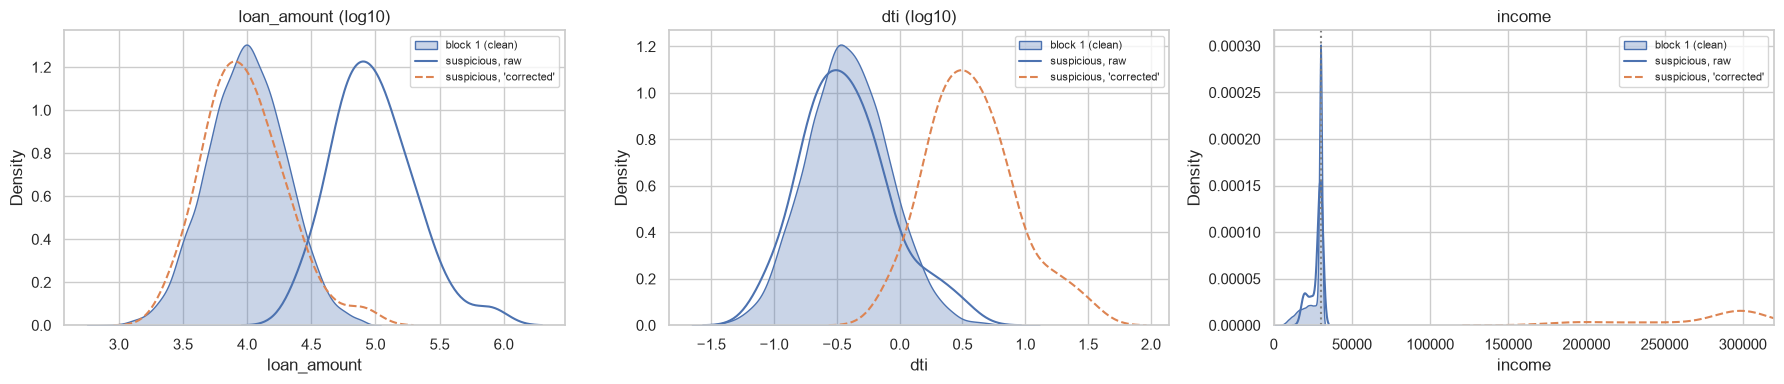

raw loans exactly 800,000: 2 | block-1 loans exactly 80,000 (the cap): 13


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (col, title) in zip(axes, [("loan_amount", "loan_amount (log10)"), ("dti", "dti (log10)"), ("income", "income")]):
    tf = np.log10 if col != "income" else (lambda v: v)
    sns.kdeplot(tf(b1[col].dropna()), ax=ax, label="block 1 (clean)", fill=True, alpha=0.3)
    sns.kdeplot(tf(sus[col].dropna()), ax=ax, label="suspicious, raw")
    fix = {"loan_amount": sus.loan_amount / 10, "dti": sus.dti * 10, "income": sus_inc * 10}[col]
    sns.kdeplot(tf(fix), ax=ax, label="suspicious, 'corrected'", ls="--")
    ax.set_title(title); ax.legend(fontsize=8)
axes[2].axvline(30_000, c="grey", ls=":"); axes[2].set_xlim(0, 320_000)
plt.tight_layout(); plt.show()
print("raw loans exactly 800,000:", (sus.loan_amount == 800_000).sum(),
      "| block-1 loans exactly 80,000 (the cap):", (b1.loan_amount == 80_000).sum())

**Only H1 fits.**

| Hypothesis | Raw value abnormal? | Corrected value normal? | Verdict |
|---|---|---|---|
| **H1: loan ×10** | **Yes.** Median about 89k vs 9.9k in block 1; 44 of 80 above the 80k cap; KS p ≈ 1e-86 | **Yes.** Loan ÷ 10 matches block 1 (KS p ≈ 0.76) and respects the cap | ✅ |
| H2: dti ÷10 | No. Raw `dti` matches block 1 (KS p ≈ 0.83) | No. `dti × 10` is far off (KS p ≈ 1e-74), and 10 rows would exceed block 1's maximum `dti` | ❌ |
| H3: income ÷10 | No. Raw incomes look normal (most sit at the 30k cap) | Impossible. `income × 10` breaks the 30k cap in **all 73** rows | ❌ |

2 more clues point the same way:
- **The two 800,000 values are exactly the 80,000 product cap × 10.** Block 1 has 13 loans at exactly 80,000.
- **The 7 missing-income rows** can't be checked against income, but their raw loans (67k–355k) fall in the normal range after ÷10, and their `dti` values already look normal.

This is the explanation best supported by the data. It isn't a certainty, and confirming it with the data owner is part of verdict condition 1 (notebook 03).

**Why it matters:** the model uses `dti`, not `loan_amount`. Under H2, 80 clients would have a wrong value in the model's top driver. Under H1, which the evidence supports, `dti` was never touched, so it is clean in every row, and only the loan amount (and the 7 rebuilt incomes) needed fixing.

## 8. Target leakage check — `recovery_flag_after_90d`

In [24]:
ct = pd.crosstab(df.recovery_flag_after_90d, df[TARGET], margins=True)
ct

default,0,1,All
recovery_flag_after_90d,,,
0,16365,487,16852
1,489,2659,3148
All,16854,3146,20000


In [25]:
agree = (df.recovery_flag_after_90d == df[TARGET]).mean()
print(f"recovery_flag prevalence: {df.recovery_flag_after_90d.mean():.4f}")
print(f"default prevalence:       {df[TARGET].mean():.4f}")
print(f"corr(recovery_flag, default): {df.recovery_flag_after_90d.corr(df[TARGET]):.3f}")
print(f"rows where flag == default:   {agree:.1%}")
print()
print(pd.crosstab(df.past_due_90, df.recovery_flag_after_90d, margins=True))

recovery_flag prevalence: 0.1574
default prevalence:       0.1573
corr(recovery_flag, default): 0.816
rows where flag == default:   95.1%

recovery_flag_after_90d      0     1    All
past_due_90                                
0                        16177  2877  19054
1                          666   263    929
2                            9     8     17
All                      16852  3148  20000


**`recovery_flag_after_90d` is target leakage and must be excluded.**
- Its prevalence (15.74%) is practically the default rate (15.73%). It equals the target in **95.1%** of rows (correlation 0.82).
- By definition it records an event that happens **after** the client reaches 90+ DPD, which is after (or at) the default event. It would not be available when a loan application is scored.
- It does not match the client's own history either: 2,877 clients have the flag but 0 `past_due_90` loans, so it isn't a pre-application feature.

Including it would give an artificially excellent model (AUC ≈ 0.95, Gini ≈ 0.90; quantified in notebook 03) that would collapse in production.

## 9. Univariate predictive power

In [26]:
features = [c for c in df.columns if c not in (TARGET, "block")]
iv = information_value(df[features], df[TARGET]).to_frame("IV")
iv["strength"] = pd.cut(iv.IV, [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
                        labels=["useless", "weak", "medium", "strong", "suspicious (>0.5)"])
iv["corr_with_target"] = df[iv.index].corrwith(df[TARGET])
iv

,IV,strength,corr_with_target
recovery_flag_after_90d,4.2489,suspicious (>0.5),0.8160
past_default,0.2188,medium,0.1964
dti,0.1344,medium,0.1732
loan_amount,0.0950,weak,0.0924
past_due_60,0.0831,weak,0.1134
past_due_30,0.0551,weak,0.0896
past_due_90,0.0524,weak,0.0948
income,0.0383,weak,-0.0723
region_risk,0.0375,weak,0.0703
credit_utilization,0.0111,useless,0.0366


Interpreting Information Value (IV) with the usual rule of thumb (< 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, > 0.5 suspicious):
- `recovery_flag_after_90d` has an IV far above 0.5, which confirms the leakage.
- Without it, the strongest drivers are **`dti`, `past_default`, `loan_amount`, the DPD counts, `income` and `region_risk`**.
- `age`, `interest_rate`, `employment_years`, `num_loans` and `client_history_in_bank` carry almost no signal on their own. In particular, **interest rate not being linked to risk is unusual**, since lenders normally price for risk.

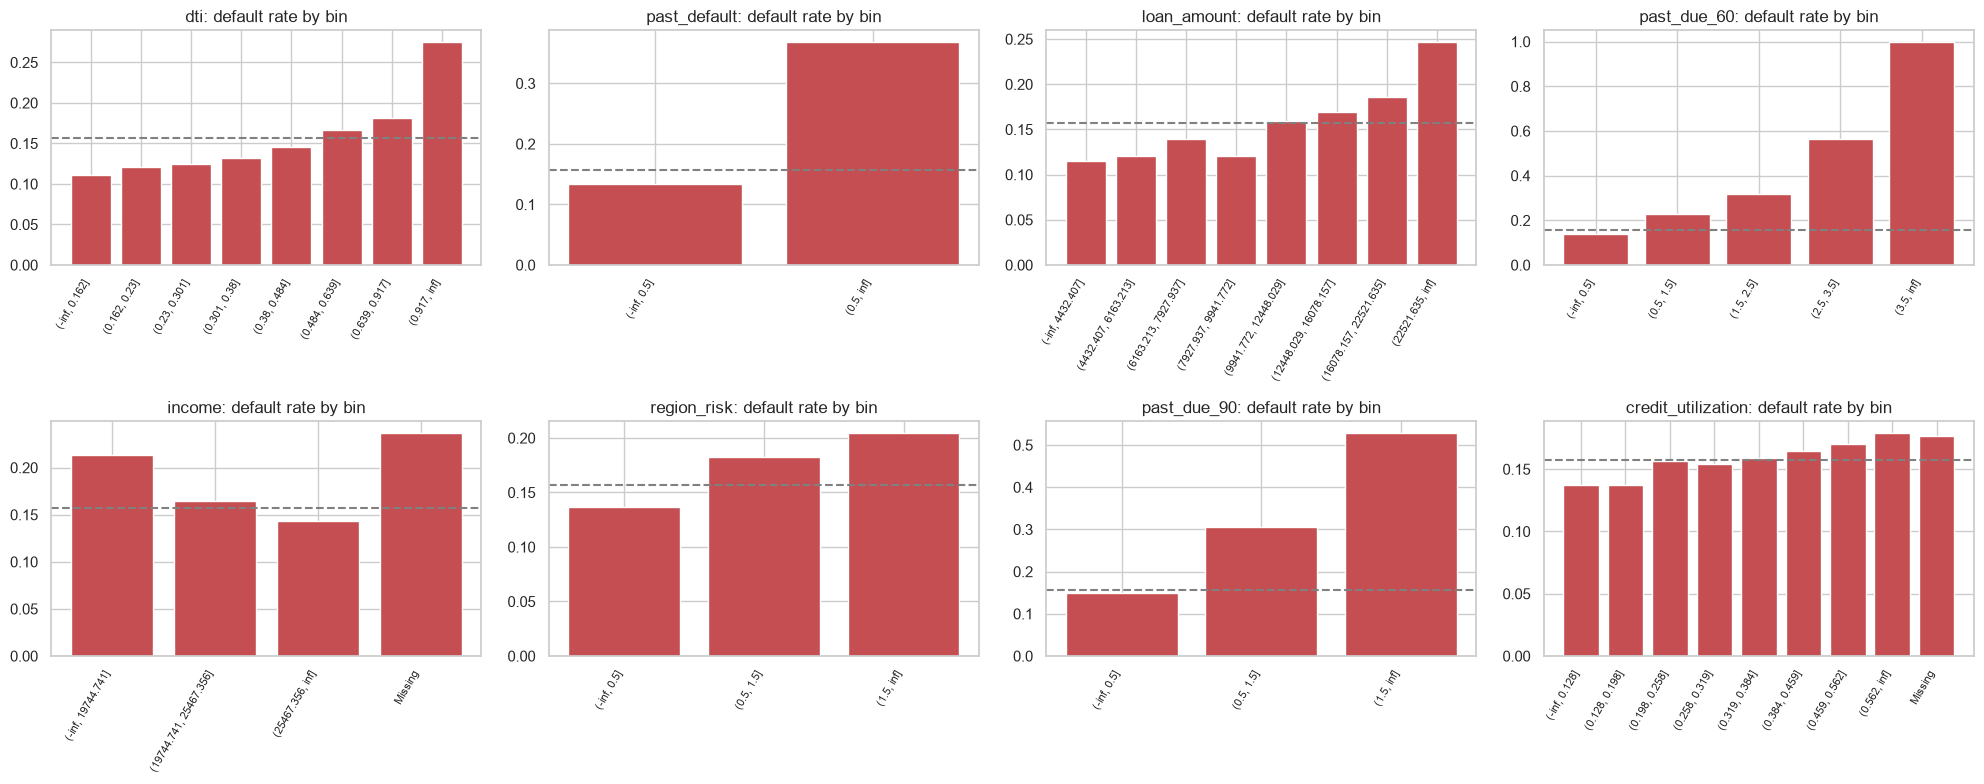

In [27]:
plot_feats = ["dti", "past_default", "loan_amount", "past_due_60", "income", "region_risk", "past_due_90", "credit_utilization"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, plot_feats):
    t = woe_table(df[c], df[TARGET], max_bins=8)
    ax.bar(range(len(t)), t.bad_rate, color="#C44E52")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=60, ha="right", fontsize=8)
    ax.axhline(df[TARGET].mean(), ls="--", c="grey")
    ax.set_title(f"{c}: default rate by bin")
plt.tight_layout(); plt.show()

The default rate rises steadily with `dti`, `loan_amount`, DPD counts, `past_default` and `region_risk`, and falls with `income`. These relationships are monotonic and make business sense, which supports **monotone constraints** in the tree models and a WoE scorecard.

### 9.1 Low-cardinality features: default rate per level with 95% intervals
Bins with few clients (e.g. 4 past-due loans) can show extreme default rates by chance. Wilson intervals show which differences are real.

In [28]:
low_card = ["past_due_30", "past_due_60", "past_due_90", "past_default", "num_loans", "region_risk"]
lc = pd.concat({c: rate_table(df[c], df[TARGET]) for c in low_card}, names=["feature", "level"])
lc

n  defaults  default_rate  ci_low  ci_high
feature      level                                                
past_due_30  0      13367      1838        0.1375  0.1318   0.1434
             1       5378       990        0.1841  0.1740   0.1947
             2       1096       267        0.2436  0.2191   0.2699
             3        151        48        0.3179  0.2489   0.3959
             4          8         3        0.3750  0.1368   0.6943
past_due_60  0      16373      2280        0.1393  0.1340   0.1446
             1       3280       749        0.2284  0.2143   0.2430
             2        323       103        0.3189  0.2704   0.3716
             3         23        13        0.5652  0.3681   0.7437
             4          1         1        1.0000  0.2065   1.0000
past_due_90  0      19054      2853        0.1497  0.1447   0.1549
             1        929       284        0.3057  0.2769   0.3361
             2         17         9        0.5294  0.3096   0.7383
past_default 0      17951      2390        0.1331  0.1282   0.1382
             1       2049       756        0.3690  0.3483   0.3901
num_loans    0       1021       191        0.1871  0.1643   0.2121
             1       2999       474        0.1581  0.1454   0.1715
             2       4503       692        0.1537  0.1434   0.1645
             3       4440       732        0.1649  0.1542   0.1761
             4       3307       516        0.1560  0.1441   0.1688
             5       1987       292        0.1470  0.1321   0.1632
             6       1023       141        0.1378  0.1181   0.1603
             7        466        67        0.1438  0.1148   0.1785
             8        177        26        0.1469  0.1023   0.2065
             9         52        13        0.2500  0.1523   0.3821
             10        15         1        0.0667  0.0119   0.2982
             11         8         1        0.1250  0.0224   0.4709
             12         1         0        0.0000  0.0000   0.7935
             13         1         0        0.0000  0.0000   0.7935
region_risk  0      12050      1648        0.1368  0.1307   0.1430
             1       5866      1071        0.1826  0.1729   0.1927
             2       2084       427        0.2049  0.1881   0.2228

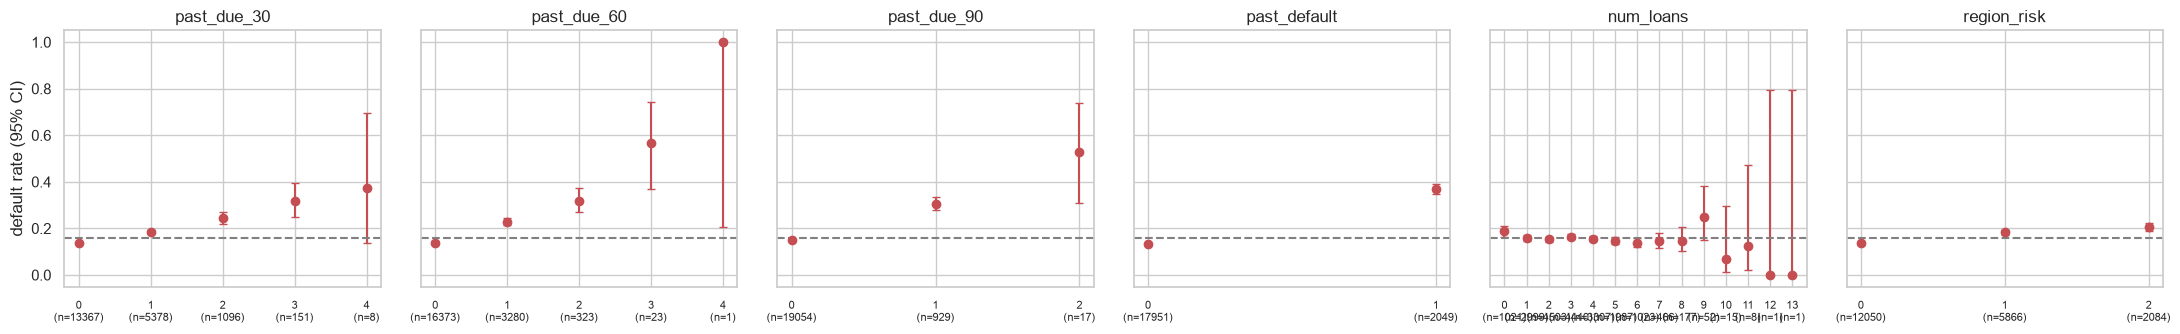

In [29]:
fig, axes = plt.subplots(1, len(low_card), figsize=(22, 3.5), sharey=True)
for ax, c in zip(axes, low_card):
    t = lc.loc[c]
    ax.errorbar(range(len(t)), t.default_rate, yerr=[t.default_rate - t.ci_low, t.ci_high - t.default_rate],
                fmt="o", capsize=3, color="#C44E52")
    ax.set_xticks(range(len(t)), [f"{v}\n(n={n})" for v, n in zip(t.index, t.n)], fontsize=8)
    ax.axhline(df[TARGET].mean(), ls="--", c="grey")
    ax.set_title(c)
axes[0].set_ylabel("default rate (95% CI)")
plt.tight_layout(); plt.show()

- **DPD counts and `past_default`** increase the default rate monotonically, and the intervals of neighbouring levels mostly don't overlap. The top levels are tiny (`past_due_30 = 4`: n = 8, `past_due_60 = 4`: n = 1, `past_due_90 = 2`: n = 17), so their point estimates (37–100%) mean little on their own. Tree models and WoE binning group them automatically. A linear model would benefit from capping at 3+ (30/60) and 2+ (90).
- **`num_loans` has no clear trend**: everything between 1 and 8 loans sits inside 14–17%. Clients with 0 loans are slightly higher (18.7%, CI 16.4–21.2%), and levels ≥ 9 are noise (n ≤ 52).
- **`region_risk`**: the default rate rises with the code, 13.7% → 18.3% → 20.5%, and the 0-vs-1 intervals are well separated. So risk is ordered by region, but **not in equal steps**: about +0.34 log-odds from 0→1 and only +0.14 from 1→2. Using the raw code as one linear term would force equal steps, over-predicting region 2 and under-predicting region 1.
  - **Decision:** treat `region_risk` as **categorical** and one-hot encode it (region 0 = reference). This removes the equal-step assumption for 1 extra parameter in logistic regression. Trees are unaffected.
  - We don't know what the codes mean. Their order is inferred from the data, not from documentation, and needs confirmation.

## 10. Correlations between features

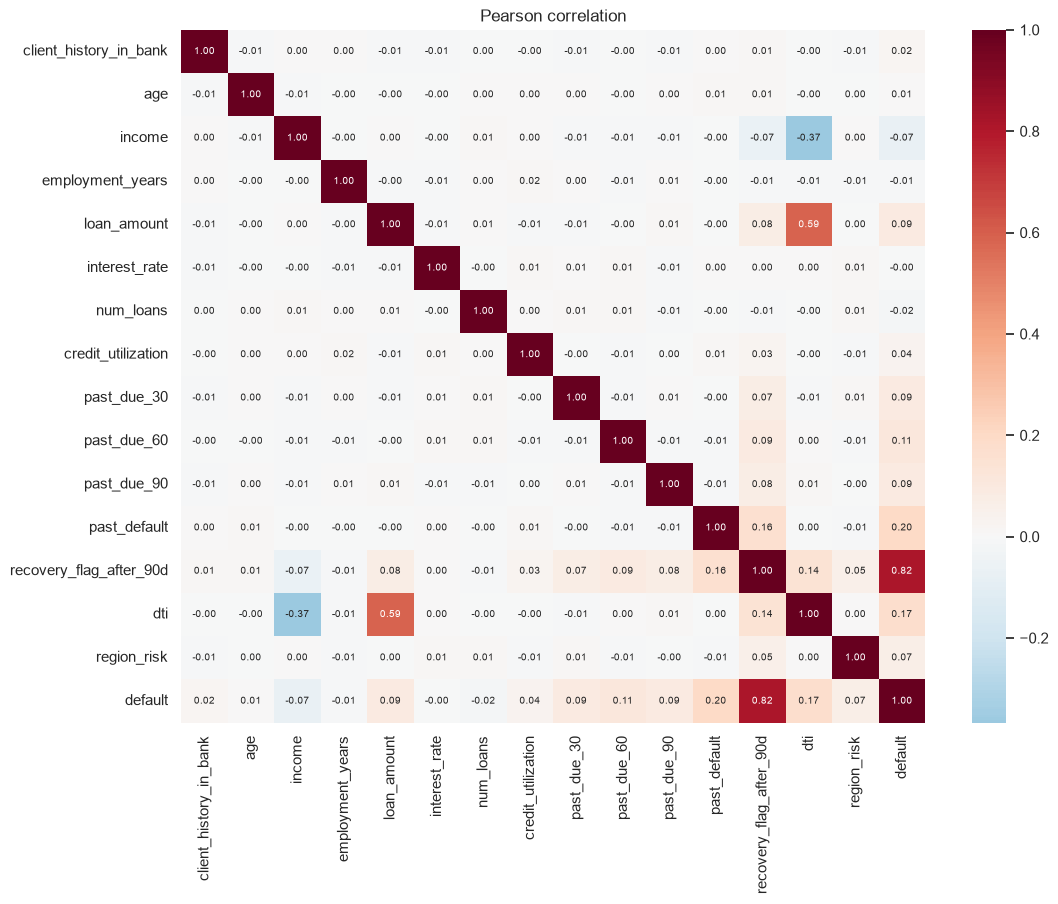

In [30]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.drop(columns="block").corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Pearson correlation")
plt.show()

Multicollinearity is low: the only notable pairs are `dti`–`loan_amount` (0.59) and `dti`–`income` (−0.37), both expected since `dti` = loan / income. Apart from those, the features are nearly uncorrelated with each other, which again suggests a synthetic dataset.

## 11. Summary of findings → actions (implemented in `pd_model.data.cleaning` and the preprocessor)

| # | Issue | Severity | Action |
|---|---|---|---|
| 1 | `recovery_flag_after_90d` is post-default information (95% agreement with target) | **Critical** | Drop from features |
| 2 | Non-unique index: file is two concatenated blocks (13k + 7k); block 2 contains all injected errors | High | Reset index; keep `block` for validation segmentation only |
| 3 | `income` missing (700, block 2), **MNAR**: every income below ≈16.8k was removed | High | **Reconstruct exactly** as `loan_amount / dti`; keep `income_reconstructed` flag (validation only) |
| 4 | 80 `loan_amount` values ×10 in block 2 (incl. 800k) | High | **Correct exactly** (÷10), detected via the `dti` identity |
| 5 | `income` censored at 30,000 (62.5% of rows) | High | Keep, add `income_capped` flag; document as limitation |
| 6 | `dti` is actually loan-to-income for this loan; deterministic link with loan & income | Medium | Document; avoid using all three in a linear model |
| 7 | `age == 99` placeholder (120 rows, block 2) | Medium | Set to missing → train-median impute + flag |
| 8 | `age` clipped to [21, 75]; `interest_rate` floored at 3%; loans capped at 80k | Low | Keep; document |
| 9 | `dti` heavy tail (genuine) | Low | Winsorise at train p99.5 (for logistic regression robustness) |
| 10 | `credit_utilization` missing (17 rows, block 2) | Low | Train-median impute |
| 11 | DPD buckets not nested; DPD > num_loans; implausible age/tenure/employment combinations (equally frequent in both blocks, so part of how the data was generated) | Medium (model risk) | Keep rows; flag; confirm definitions with data owner; check performance on affected segment |
| 12 | Weak signal overall (best IV = 0.22, only 2 features above 0.1), no time stamp | Model risk | Expect moderate Gini (≈ 0.4); no out-of-time validation possible |
| 13 | `region_risk` code meaning unknown; risk rises monotonically but in unequal steps | Low | Categorical, one-hot encoded (reference = 0); confirm meaning with data owner |
| 14 | Sparse top levels of DPD counts (n = 1–17) | Low | Trees/WoE group them; cap at 3+/2+ for any linear model |

## 12. Open questions for the data owner

Everything above was inferred from the data alone. These points need confirmation before the model can be approved; they feed the verdict conditions in notebook 03.

| # | Topic | Question | What we assumed meanwhile |
|---|---|---|---|
| 1 | Prediction point and target | At what point is the PD score produced (application? annual review?), and what is the exact default definition and observation horizon? | Application-time scoring; `default` = 90+ DPD within the horizon. No time stamp, so no out-of-time validation. |
| 2 | `recovery_flag_after_90d` | Is it populated only after a client reaches 90+ DPD, i.e. after the target event? | Yes, so it is target leakage and dropped (§8). |
| 3 | File provenance | Why is the file two blocks (13,000 + 7,000) with a restarting index, and why does only block 2 contain errors? | Same population with errors injected (§1.2). Block used only for validation segmentation. |
| 4 | Loan amounts ×10 | Are the 80 loans that break `dti = loan / income` by a factor of 10 really inflated loans (e.g. a units or keying error), rather than wrong `dti` or income? | Loan ×10, corrected by ÷10 (§7.2). |
| 5 | Income | Is income top-coded at 30,000? What are the units and currency? Why are all block-2 incomes below ≈16.8k missing? | Top-coded (`income_capped` flag). Missing values rebuilt as `loan / dti`. |
| 6 | `dti` | Is `dti` meant to be total debt-to-income? In the data it is exactly this loan's amount / income. | Treated as loan-to-income. |
| 7 | DPD fields | Are `past_due_30/60/90` exclusive buckets ("worst status") or cumulative counts? Over what window? Do they include closed loans? | Exclusive buckets (§7). |
| 8 | `num_loans`, `credit_utilization`, `past_default` | Does `num_loans` count only active loans? Does utilisation include cards and overdrafts? How can `past_default = 1` occur without any past-due history? | Active loans only; utilisation includes non-loan products; definitions are a documented limitation. |
| 9 | `region_risk` | What do codes 0/1/2 mean, and are they ordered by risk? | Categorical, one-hot encoded; risk rises with the code but in unequal steps (§9.1). |
| 10 | `age` | Is 99 an "unknown" code? Is age clipped to 21–75 by policy? | 99 = missing (imputed + flagged); clipping kept. |
| 11 | Pricing | Why isn't `interest_rate` related to risk (IV ≈ 0)? Is the 3% floor a product minimum? | Kept as a feature; documented as an anomaly. |
| 12 | Tenure and employment | What unit is `client_history_in_bank` (months?)? Are the 970 employment > age − 14 and 676 tenure > adulthood cases known issues, or is the dataset synthetic? | Rows kept, flagged for validation segmentation only. |